In [1]:
import pandas as pd 
import numpy as np
from matplotlib import pyplot as plt

from rdkit import Chem
from rdkit.Chem import AllChem
from tqdm import tqdm

## Batch 1 Preprocessing

### Luminiscense Data

In [2]:
batch_1_lumi_data = pd.read_excel("/n/scratch/users/a/aw274/data/tb_data/raw_data/Batch1_lumi.xlsx")
batch_1_lumi_data

/home/aw274/.conda/envs/dlad_env/lib/python3.9/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


,Molecule Name,SMILES,IUPAC,LGCY Batch Name,Mtb_SAC3HTS_20uM_7H9DextroseAcetate: Raw Data % inhibition (%),Mtb_SAC3HTS_20uM_7H9DextroseAcetate: Raw Data z score
0,SACC-0413842,CN(C)CCCO,3-(dimethylamino)-1-propanol,5115929,30.46,-0.90
1,SACC-0413841,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3Cl)N3C(=NC(...,8-(o-chlorophenyl)-5-methyl-11-[(4-pyridyl)met...,9220052,-12.49,0.67
2,SACC-0413841,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3Cl)N3C(=NC(...,8-(o-chlorophenyl)-5-methyl-11-[(4-pyridyl)met...,9220052,4.18,0.13
3,SACC-0413840,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3OC)N3C(N=C2...,"8-(o-methoxyphenyl)-11-[(4-pyridyl)methyl]-2,4...",9245911,16.35,-0.26
4,SACC-0413840,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3OC)N3C(N=C2...,"8-(o-methoxyphenyl)-11-[(4-pyridyl)methyl]-2,4...",9245911,-15.30,0.76
...,...,...,...,...,...,...
19052,SACC-0019416,CC(C)N1C(CNC(C)=O)=NC2=CC=CC=C12,"N-[(1-isopropyl-1H-1,3-benzimidazol-2-yl)methy...",MLS000101352-01,19.37,-0.38
19053,SACC-0015699,CC(C)(C)C1=NC2=C(C3=CC=C(Cl)C=C3)C=NN2C(NCC2=C...,[(2-pyridyl)methyl][5-(tert-butyl)-3-(p-chloro...,GATB_SAM002768460,98.98,-2.91
19054,SACC-0015699,CC(C)(C)C1=NC2=C(C3=CC=C(Cl)C=C3)C=NN2C(NCC2=C...,[(2-pyridyl)methyl][5-(tert-butyl)-3-(p-chloro...,GATB_SAM002768460,100.61,-2.96
19055,SACC-0006416,C(OC1=CC=C(C2=NNN=N2)C=C1)C1=NNN=N1,5-{p-[(2H-tetraazol-5-yl)methoxy]phenyl}-2H-te...,PBCHM_1286,25.85,-0.52


### Resazurin Data

In [3]:
batch_1_resazurin_data = pd.read_excel("/n/scratch/users/a/aw274/data/tb_data/raw_data/Batch1_resazurin.xlsx")
print("Raw Batch 1 data contains: ", len(batch_1_resazurin_data), 'molecules')
batch_1_resazurin_data = batch_1_resazurin_data[['SMILES','Mtb_SAC3HTS_20uM_7H9DextroseAcetate_Resazurin: Raw Data % inhibition (%)']]
batch_1_resazurin_data = batch_1_resazurin_data.rename(columns={'Mtb_SAC3HTS_20uM_7H9DextroseAcetate_Resazurin: Raw Data % inhibition (%)':'inhibition'})
batch_1_resazurin_data = batch_1_resazurin_data.dropna()
print("Raw Batch 1 data contains: ", len(batch_1_resazurin_data), "molecules after dropping molecules without SMILES structure")
batch_1_resazurin_data


/home/aw274/.conda/envs/dlad_env/lib/python3.9/site-packages/openpyxl/styles/stylesheet.py:226: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Raw Batch 1 data contains:  9975 molecules
Raw Batch 1 data contains:  9975 molecules after dropping molecules without SMILES structure


,SMILES,inhibition
0,CN(C)CCCO,-6.41
1,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3Cl)N3C(=NC(...,-4.30
2,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3OC)N3C(N=C2...,-1.27
3,O=C(N(CC1=CC=NC=C1)CCC1=CC=C(OC)C=C1)N[C@@H]1[...,2.38
4,O(C1=CC=CC=C1)CCN1CCN(C2=NC=NC3=C2CCNCC3)CC1,5.32
...,...,...
9970,CCCC(=O)N1CCN(C2=CC=C(NC(=O)C3=CC=C(C4=CC=C(Cl...,94.85
9971,CC1=CC=CC=C1CSC1=NC(O)=C(C)N=N1,2.56
9972,CC(C)N1C(CNC(C)=O)=NC2=CC=CC=C12,3.20
9973,CC(C)(C)C1=NC2=C(C3=CC=C(Cl)C=C3)C=NN2C(NCC2=C...,100.55


In [4]:
batch_1_resazurin_data[batch_1_resazurin_data.duplicated(subset = ['SMILES'], keep = False)] ## No duplicating molecules in batch 1 

,SMILES,inhibition


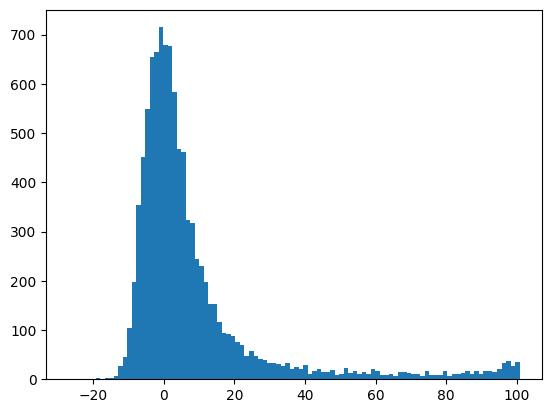

In [5]:
plt.hist(batch_1_resazurin_data['inhibition'].sort_values(), bins = 100)
plt.show()

## Batch 2 Preprocessing (Resazurin Only)

In [6]:
batch_2_resazurin_data = pd.read_excel('/n/scratch/users/a/aw274/data/tb_data/raw_data/Batch2_resazurin.xlsx')
print("Raw Batch 2 data contains: ", len(batch_2_resazurin_data), "molecules")
batch_2_resazurin_data = batch_2_resazurin_data[['SMILES',"Sac2 HTS MC27000 on M9+NaOAc+Dextrose: Raw Data % inhibition (%)"]]
batch_2_resazurin_data = batch_2_resazurin_data.rename(columns={'Sac2 HTS MC27000 on M9+NaOAc+Dextrose: Raw Data % inhibition (%)':'inhibition'})
batch_2_resazurin_data = batch_2_resazurin_data.dropna()
print("Raw Batch 2 data contains: ", len(batch_2_resazurin_data), "molecules after dropping molecules without SMILES structure")

batch_2_duplicated = batch_2_resazurin_data[batch_2_resazurin_data.duplicated(subset = ['SMILES'], keep = False)]

Raw Batch 2 data contains:  52661 molecules
Raw Batch 2 data contains:  52644 molecules after dropping molecules without SMILES structure


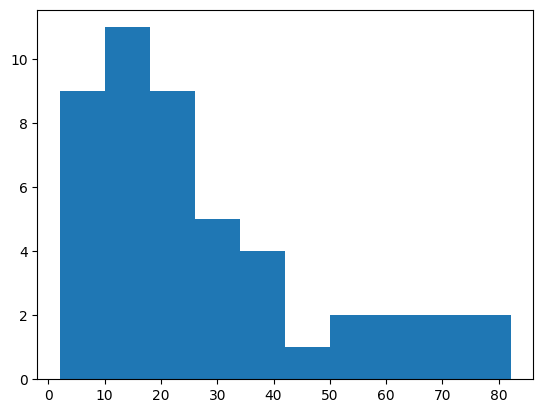

In [7]:
plt.hist(batch_2_duplicated.groupby('SMILES').diff().dropna()['inhibition'].abs())
plt.show()

In [8]:
confliction_threshold = 20

conflict_index = batch_2_duplicated.groupby(['SMILES'], as_index = True).diff().dropna()['inhibition'].abs()
conflict_index = conflict_index[conflict_index > confliction_threshold].index
conflict_smiles = set(batch_2_resazurin_data.loc[conflict_index]['SMILES'])

print(len(conflict_smiles))

25


In [9]:
batch_2_resazurin_data = batch_2_resazurin_data[~batch_2_resazurin_data['SMILES'].isin(conflict_smiles)]
print("Raw Batch 2 data contains: ", len(batch_2_resazurin_data), "molecules after dropping conflicting inhibition readouts")

batch_2_resazurin_data = batch_2_resazurin_data.groupby(['SMILES'], as_index = False).mean()
print("Raw Batch 2 data contains: ", len(batch_2_resazurin_data), "molecules after averaging duplicated readouts")

Raw Batch 2 data contains:  52594 molecules after dropping conflicting inhibition readouts
Raw Batch 2 data contains:  52572 molecules after averaging duplicated readouts


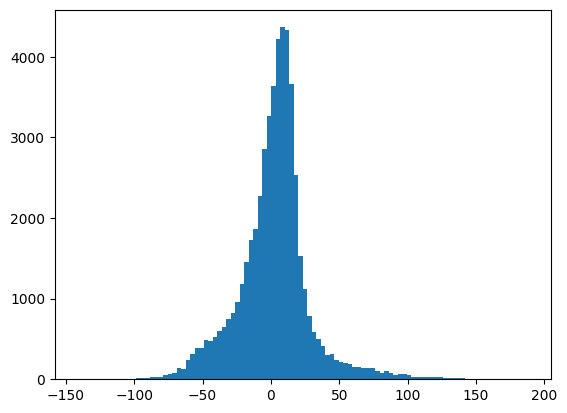

In [10]:
plt.hist(batch_2_resazurin_data['inhibition'].sort_values(), bins=100)
plt.show()

## Concatenating Batch 1 & 2

In [11]:
batch1_and_2_resazurin_data = pd.concat([batch_1_resazurin_data,batch_2_resazurin_data])
batch1_and_2_resazurin_data

,SMILES,inhibition
0,CN(C)CCCO,-6.41
1,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3Cl)N3C(=NC(...,-4.30
2,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3OC)N3C(N=C2...,-1.27
3,O=C(N(CC1=CC=NC=C1)CCC1=CC=C(OC)C=C1)N[C@@H]1[...,2.38
4,O(C1=CC=CC=C1)CCN1CCN(C2=NC=NC3=C2CCNCC3)CC1,5.32
...,...,...
52567,[O-][N+]1=CC=CC(C(=O)N2CC[C@]3(C2)CCCN(CC2CCCC...,-8.32
52568,[O-][N+]1=CC=CC=C1SCC1=CC=C(CSC2=CC=CC=[N+]2[O...,24.60
52569,[S-]/C(NCC1=CC=C2OCOC2=C1)=C(\C(=O)C1=CC=C(Cl)...,2.80
52570,c1c(C2=CC=CC=C2)nc2nc3[nH]c4ccccc4c3nn12,21.55


In [12]:
batch1_and_2_resazurin_data[batch1_and_2_resazurin_data.duplicated(subset=['SMILES'])] ## No duplicated molecules between set 1 and 2

,SMILES,inhibition


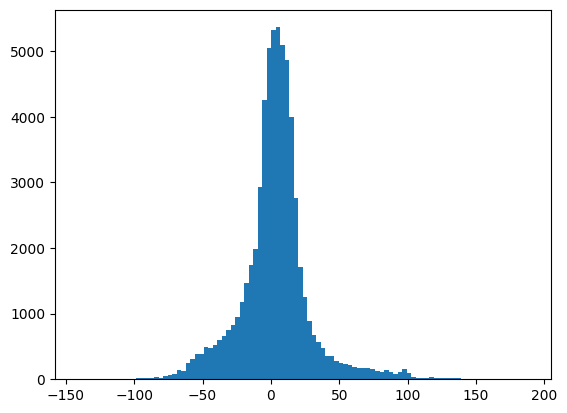

In [13]:
plt.hist(batch1_and_2_resazurin_data['inhibition'].sort_values(), bins=100)
plt.show()

In [14]:
## Min-Max Normalization
batch1_and_2_resazurin_data['normalized_inhibition'] = (batch1_and_2_resazurin_data['inhibition'] - batch1_and_2_resazurin_data['inhibition'].min()) / (batch1_and_2_resazurin_data['inhibition'].max() - batch1_and_2_resazurin_data['inhibition'].min())
batch1_and_2_resazurin_data

,SMILES,inhibition,normalized_inhibition
0,CN(C)CCCO,-6.41,0.409743
1,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3Cl)N3C(=NC(...,-4.30,0.416143
2,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3OC)N3C(N=C2...,-1.27,0.425334
3,O=C(N(CC1=CC=NC=C1)CCC1=CC=C(OC)C=C1)N[C@@H]1[...,2.38,0.436406
4,O(C1=CC=CC=C1)CCN1CCN(C2=NC=NC3=C2CCNCC3)CC1,5.32,0.445324
...,...,...,...
52567,[O-][N+]1=CC=CC(C(=O)N2CC[C@]3(C2)CCCN(CC2CCCC...,-8.32,0.403949
52568,[O-][N+]1=CC=CC=C1SCC1=CC=C(CSC2=CC=CC=[N+]2[O...,24.60,0.503807
52569,[S-]/C(NCC1=CC=C2OCOC2=C1)=C(\C(=O)C1=CC=C(Cl)...,2.80,0.437680
52570,c1c(C2=CC=CC=C2)nc2nc3[nH]c4ccccc4c3nn12,21.55,0.494555


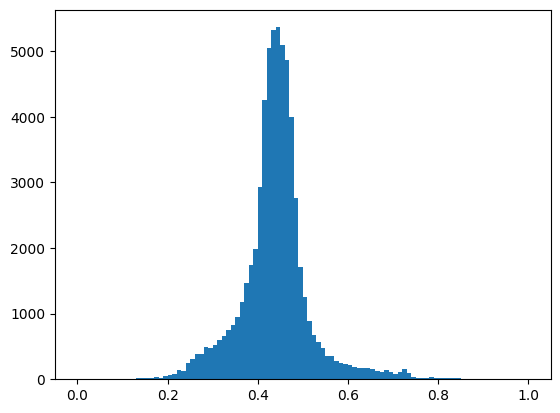

In [16]:
plt.hist(batch1_and_2_resazurin_data['normalized_inhibition'].sort_values(), bins=100)
plt.show()

### Generate 3d Structure

In [18]:
smiles = [smi for smi in batch1_and_2_resazurin_data.SMILES]
mols = [Chem.MolFromSmiles(smi) for smi in batch1_and_2_resazurin_data.SMILES]
tb_inhibition = [label for label in batch1_and_2_resazurin_data.inhibition]
normalized_tb_inhibition = [label for label in batch1_and_2_resazurin_data.normalized_inhibition]

hmols = []
for m in range(len(mols)):
    if mols[m] is not None:
        hmols.append(Chem.AddHs(mols[m]))
    else:
        smiles[m] = None
        tb_inhibition[m] = None
        normalized_tb_inhibition[m] = None
        continue

smiles = [i for i in smiles if i is not None]
tb_inhibition = [i for i in tb_inhibition if i is not None]
normalized_tb_inhibition = [i for i in normalized_tb_inhibition if i is not None]

print(len(hmols))
print(len(smiles))
print(len(tb_inhibition))
print(len(normalized_tb_inhibition))

print("Resazurin Data contains: ", len(hmols), "molecules after remove the molecules fail to read by rdkit" )

[15:06:38] Explicit valence for atom # 9 N, 4, is greater than permitted
[15:06:47] Explicit valence for atom # 21 N, 4, is greater than permitted
[15:06:47] Explicit valence for atom # 22 N, 4, is greater than permitted
[15:07:37] Explicit valence for atom # 21 O, 3, is greater than permitted
[15:07:40] Explicit valence for atom # 0 N, 4, is greater than permitted


62542
62542
62542
62542
Resazurin Data contains:  62542 molecules after remove the molecules fail to read by rdkit


In [22]:
optimize_status_list = []

for i in tqdm(range(len(hmols))):
    embed_status = AllChem.EmbedMolecule(hmols[i], AllChem.ETKDG())
    if embed_status != 0:
        hmols[i] = None
        smiles[i] = None
        tb_inhibition[i] = None
        normalized_tb_inhibition[i] = None
        continue
    else:
        optimize_status = AllChem.UFFOptimizeMolecule(hmols[i],1000)
        optimize_status_list.append(optimize_status)

        if optimize_status != 0:
            print(f"Optimization Failed on Molecule Index: {i}")
            hmols[i] = None
            smiles[i] = None
            tb_inhibition[i] = None
            normalized_tb_inhibition[i] = None
    
hmols = [i for i in hmols if i is not None]
smiles = [i for i in smiles if i is not None]
tb_inhibition = [i for i in tb_inhibition if i is not None]
normalized_tb_inhibition = [i for i in normalized_tb_inhibition if i is not None]

print(len(hmols))
print(len(smiles))
print(len(tb_inhibition))
print(len(normalized_tb_inhibition))
    
print(f"RDKit Optimization failed on {sum(optimize_status_list)} Molecules")

  0%|          | 0/62542 [00:00<?, ?it/s]

 52%|█████▏    | 32615/62542 [1:20:22<1:35:36,  5.22it/s]  

Optimization Failed on Molecule Index: 32613


 57%|█████▋    | 35911/62542 [1:30:58<59:44,  7.43it/s]   [16:41:05] UFFTYPER: Unrecognized charge state for atom: 2
[16:41:05] UFFTYPER: Unrecognized charge state for atom: 2
 57%|█████▋    | 35931/62542 [1:30:59<37:36, 11.79it/s][16:41:06] UFFTYPER: Unrecognized charge state for atom: 14
[16:41:06] UFFTYPER: Unrecognized charge state for atom: 14
 65%|██████▌   | 40782/62542 [1:50:02<1:46:19,  3.41it/s]  

Optimization Failed on Molecule Index: 40780


...

Optimization Failed on Molecule Index: 40843


 67%|██████▋   | 42070/62542 [1:55:42<1:15:37,  4.51it/s] [17:05:49] UFFTYPER: Unrecognized charge state for atom: 6
[17:05:49] UFFTYPER: Unrecognized charge state for atom: 6
 69%|██████▊   | 42915/62542 [1:59:56<2:54:40,  1.87it/s] 

Optimization Failed on Molecule Index: 42914


 75%|███████▍  | 46782/62542 [2:10:14<27:26,  9.57it/s]  [17:20:21] UFFTYPER: Unrecognized charge state for atom: 5
[17:20:21] UFFTYPER: Unrecognized charge state for atom: 5
 76%|███████▋  | 47746/62542 [2:14:30<16:31, 14.93it/s]   [17:24:37] UFFTYPER: Unrecognized charge state for atom: 1
[17:24:37] UFFTYPER: Unrecognized charge state for atom: 1
[17:24:37] UFFTYPER: Unrecognized charge state for atom: 1
[17:24:37] UFFTYPER: Unrecognized charge state for atom: 1
100%|██████████| 62542/62542 [2:44:48<00:00,  6.32it/s]   

62498
62498
62498
62498
RDKit Optimization failed on 4 Molecules


In [23]:
batch1_and_2_resazurin_data = batch1_and_2_resazurin_data[batch1_and_2_resazurin_data['SMILES'].isin(smiles)]
batch1_and_2_resazurin_data

,SMILES,inhibition,normalized_inhibition
0,CN(C)CCCO,-6.41,0.409743
1,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3Cl)N3C(=NC(...,-4.30,0.416143
2,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3OC)N3C(N=C2...,-1.27,0.425334
3,O=C(N(CC1=CC=NC=C1)CCC1=CC=C(OC)C=C1)N[C@@H]1[...,2.38,0.436406
4,O(C1=CC=CC=C1)CCN1CCN(C2=NC=NC3=C2CCNCC3)CC1,5.32,0.445324
...,...,...,...
52567,[O-][N+]1=CC=CC(C(=O)N2CC[C@]3(C2)CCCN(CC2CCCC...,-8.32,0.403949
52568,[O-][N+]1=CC=CC=C1SCC1=CC=C(CSC2=CC=CC=[N+]2[O...,24.60,0.503807
52569,[S-]/C(NCC1=CC=C2OCOC2=C1)=C(\C(=O)C1=CC=C(Cl)...,2.80,0.437680
52570,c1c(C2=CC=CC=C2)nc2nc3[nH]c4ccccc4c3nn12,21.55,0.494555


In [24]:
writer = Chem.SDWriter('/n/scratch/users/a/aw274/data/tb_data/raw_data/regression_data/TB_inhibition_resazurin_62498_molecules_3d.sdf')

print(f">>>>> Successfully Converted {len(hmols)} molecules into 3-D Structure >>>>>")

print(">>>>> Saving to File >>>>>")
for n in tqdm(range(len(hmols))):
    hmols[n].SetProp("_SMILES","%s"%smiles[n])
    hmols[n].SetProp("_tb_inhibition","%s"%tb_inhibition[n])
    writer.write(hmols[n])
    
writer.close()

>>>>> Successfully Converted 62498 molecules into 3-D Structure >>>>>
>>>>> Saving to File >>>>>


100%|██████████| 62498/62498 [00:22<00:00, 2752.55it/s]


In [25]:
writer = Chem.SDWriter('/n/scratch/users/a/aw274/data/tb_data/raw_data/regression_data/normalized_TB_inhibition_resazurin_62498_molecules_3d.sdf')

print(f">>>>> Successfully Converted {len(hmols)} molecules into 3-D Structure >>>>>")

print(">>>>> Saving to File >>>>>")
for n in tqdm(range(len(hmols))):
    hmols[n].SetProp("_SMILES","%s"%smiles[n])
    hmols[n].SetProp("_tb_inhibition","%s"%tb_inhibition[n])
    hmols[n].SetProp("_normalized_tb_inhibition", "%s"%normalized_tb_inhibition[n])
    writer.write(hmols[n])
    
writer.close()

>>>>> Successfully Converted 62498 molecules into 3-D Structure >>>>>
>>>>> Saving to File >>>>>


  0%|          | 106/62498 [00:00<02:17, 452.39it/s]

100%|██████████| 62498/62498 [00:22<00:00, 2744.69it/s]


In [26]:
normalized_data = batch1_and_2_resazurin_data[['SMILES','normalized_inhibition']]
standard_data = batch1_and_2_resazurin_data[['SMILES','inhibition']]

standard_data.to_csv("/n/scratch/users/a/aw274/data/tb_data/raw_data/regression_data/TB_inhibition_resazurin_62498_molecules.csv",
                     index = False)
normalized_data.to_csv("/n/scratch/users/a/aw274/data/tb_data/raw_data/regression_data/normalized_TB_inhibition_resazurin_62498_molecules.csv",
                                   index = False)

In [27]:
standard_data

,SMILES,inhibition
0,CN(C)CCCO,-6.41
1,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3Cl)N3C(=NC(...,-4.30
2,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3OC)N3C(N=C2...,-1.27
3,O=C(N(CC1=CC=NC=C1)CCC1=CC=C(OC)C=C1)N[C@@H]1[...,2.38
4,O(C1=CC=CC=C1)CCN1CCN(C2=NC=NC3=C2CCNCC3)CC1,5.32
...,...,...
52567,[O-][N+]1=CC=CC(C(=O)N2CC[C@]3(C2)CCCN(CC2CCCC...,-8.32
52568,[O-][N+]1=CC=CC=C1SCC1=CC=C(CSC2=CC=CC=[N+]2[O...,24.60
52569,[S-]/C(NCC1=CC=C2OCOC2=C1)=C(\C(=O)C1=CC=C(Cl)...,2.80
52570,c1c(C2=CC=CC=C2)nc2nc3[nH]c4ccccc4c3nn12,21.55


In [28]:
normalized_data

,SMILES,normalized_inhibition
0,CN(C)CCCO,0.409743
1,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3Cl)N3C(=NC(...,0.416143
2,C1=CN=CC=C1CN1C(=O)C2=C(C3=CC=CC=C3OC)N3C(N=C2...,0.425334
3,O=C(N(CC1=CC=NC=C1)CCC1=CC=C(OC)C=C1)N[C@@H]1[...,0.436406
4,O(C1=CC=CC=C1)CCN1CCN(C2=NC=NC3=C2CCNCC3)CC1,0.445324
...,...,...
52567,[O-][N+]1=CC=CC(C(=O)N2CC[C@]3(C2)CCCN(CC2CCCC...,0.403949
52568,[O-][N+]1=CC=CC=C1SCC1=CC=C(CSC2=CC=CC=[N+]2[O...,0.503807
52569,[S-]/C(NCC1=CC=C2OCOC2=C1)=C(\C(=O)C1=CC=C(Cl)...,0.437680
52570,c1c(C2=CC=CC=C2)nc2nc3[nH]c4ccccc4c3nn12,0.494555


In [30]:
supply = Chem.SDMolSupplier('/n/scratch/users/a/aw274/data/tb_data/raw_data/regression_data/TB_inhibition_resazurin_62498_molecules_3d.sdf')

pos_list = []
atom_feature = []
labels = []
smiles = []
fingerprints = []
binary_labels = []

print(">>>>> Loading Data Files >>>>>")

for idx, mol in enumerate(tqdm(supply, total = len(supply))):
    smiles.append(mol.GetProp('_SMILES'))
    labels.append(float(mol.GetProp('_tb_inhibition')))
    binary_labels.append(1 if float(mol.GetProp('_tb_inhibition')) >= 40 else 0)
    mol_pos_list = []
    mol_atom_feature = []
    for i, atom in enumerate(mol.GetAtoms()):
        positions = mol.GetConformer().GetAtomPosition(i)
        mol_atom_feature.append([atom.GetAtomicNum(), atom.GetMass(), atom.GetDegree(), 
                                 atom.GetTotalDegree(), atom.GetTotalValence(), atom.GetNumRadicalElectrons(),
                                 atom.GetFormalCharge(), 1 if atom.GetIsAromatic() else 0])
        mol_pos_list.append([positions.x, positions.y, positions.z])
    pos_list.append(mol_pos_list)
    atom_feature.append(mol_atom_feature)

>>>>> Loading Data Files >>>>>


100%|██████████| 62498/62498 [01:43<00:00, 605.42it/s] 


In [37]:
print(smiles[62497])
print(labels[62497])

c1ccc2c(c1)n[n+]1c3ccccc3[nH]n21
-43.52


In [39]:
print(len(pos_list[62497]))

16
